<a href="https://colab.research.google.com/github/ReetomGogoi/GhostVision-AI/blob/feature%2Frgb/01_rgb_training.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:

import sys
import torch
import cv2

print("===== GHOSTVISION RGB ENVIRONMENT =====")
print("Python version:", sys.version.split()[0])
print("PyTorch version:", torch.__version__)
print("OpenCV version:", cv2.__version__)

if torch.cuda.is_available():
    print("GPU: AVAILABLE")
    print("GPU name:", torch.cuda.get_device_name(0))
else:
    print("GPU: NOT AVAILABLE")
    print("Running on CPU")


===== GHOSTVISION RGB ENVIRONMENT =====
Python version: 3.13.15
PyTorch version: 2.11.0+cu130
OpenCV version: 4.14.0
GPU: AVAILABLE
GPU name: Tesla T4


In [1]:

%pip install -q "datasets==3.6.0" "pyarrow==23.0.1" "pillow>=8,<13"


In [2]:

import datasets
import pyarrow
import PIL
import torch

print("===== GHOSTVISION ENVIRONMENT =====")
print("Datasets:", datasets.__version__)
print("PyArrow:", pyarrow.__version__)
print("Pillow:", PIL.__version__)
print("GPU:", torch.cuda.is_available())

try:
    from datasets import load_dataset
    print("Hugging Face Datasets: IMPORT SUCCESS")
except Exception as e:
    print("Import error:", str(e))


===== GHOSTVISION ENVIRONMENT =====
Datasets: 3.6.0
PyArrow: 23.0.1
Pillow: 12.3.0
GPU: True
Hugging Face Datasets: IMPORT SUCCESS


In [3]:

from datasets import load_dataset

print("Loading complete COD10K dataset...")

dataset = load_dataset("nobg/COD10K")

print("\n===== DATASET INFORMATION =====")
print(dataset)

for split in dataset:
    print(f"{split}: {len(dataset[split])} samples")
    print("Columns:", dataset[split].column_names)

print("\nDataset loading completed!")


Loading complete COD10K dataset...


README.md:   0%|          | 0.00/1.95k [00:00<?, ?B/s]

data/train-00000-of-00002.parquet: reconstructing file:   0%|          |  0.00B /  492MB            

data/train-00000-of-00002.parquet: downloading bytes:           |  0.00B            

data/train-00001-of-00002.parquet: reconstructing file:   0%|          |  0.00B /  454MB            

...

data/test-00001-of-00002.parquet: reconstructing file:   0%|          |  0.00B /  297MB            

data/test-00001-of-00002.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/3040 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/2026 [00:00<?, ? examples/s]


===== DATASET INFORMATION =====
DatasetDict({
    train: Dataset({
        features: ['image', 'mask'],
        num_rows: 3040
    })
    test: Dataset({
        features: ['image', 'mask'],
        num_rows: 2026
    })
})
train: 3040 samples
Columns: ['image', 'mask']
test: 2026 samples
Columns: ['image', 'mask']

Dataset loading completed!


In [1]:

# GhostVision RGB — Dataset availability check

if "dataset" in globals():
    print("COD10K dataset is available!")
    print("Training images:", len(dataset["train"]))
    print("Testing images:", len(dataset["test"]))
else:
    print("Dataset not in memory. Reloading COD10K...")

    from datasets import load_dataset
    dataset = load_dataset("nobg/COD10K")

    print("Dataset loaded!")
    print("Training images:", len(dataset["train"]))
    print("Testing images:", len(dataset["test"]))


Dataset not in memory. Reloading COD10K...


README.md:   0%|          | 0.00/1.95k [00:00<?, ?B/s]

data/train-00000-of-00002.parquet: reconstructing file:   0%|          |  0.00B /  492MB            

data/train-00000-of-00002.parquet: downloading bytes:           |  0.00B            

data/train-00001-of-00002.parquet: reconstructing file:   0%|          |  0.00B /  454MB            

...

data/test-00001-of-00002.parquet: reconstructing file:   0%|          |  0.00B /  297MB            

data/test-00001-of-00002.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/3040 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/2026 [00:00<?, ? examples/s]

Dataset loaded!
Training images: 3040
Testing images: 2026


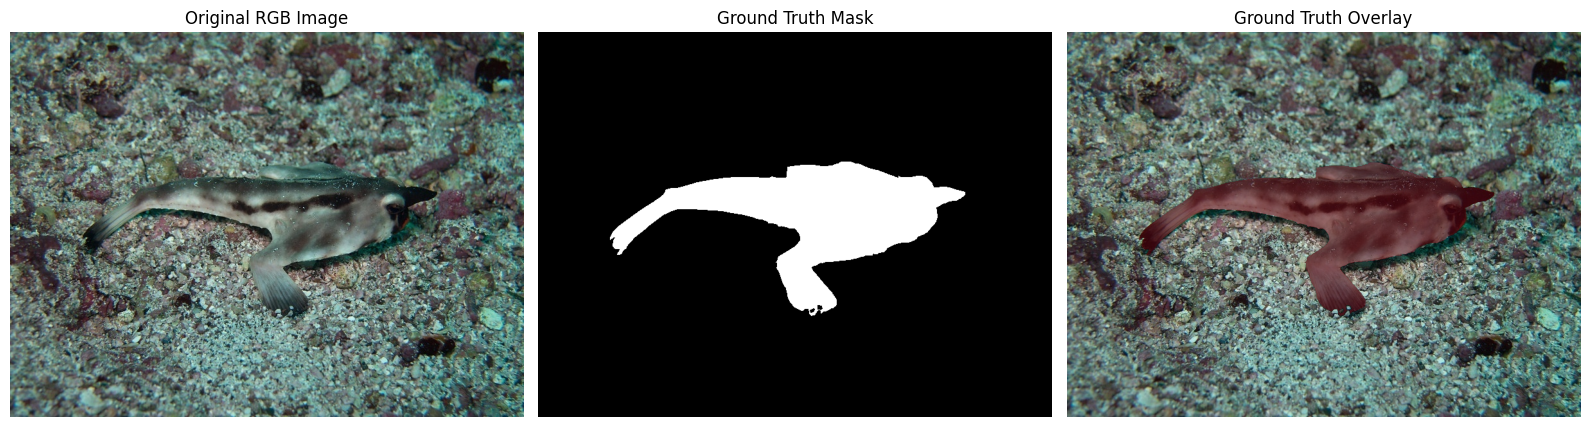

Image dimensions: (800, 600)
Mask dimensions: (800, 600)
Unique mask values: [  0 255]


In [2]:

import numpy as np
import matplotlib.pyplot as plt

sample = dataset["train"][0]

image = sample["image"].convert("RGB")
mask = sample["mask"].convert("L")

mask_array = np.array(mask)
binary_mask = (mask_array > 127).astype(np.uint8)

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

axes[0].imshow(image)
axes[0].set_title("Original RGB Image")

axes[1].imshow(binary_mask, cmap="gray", vmin=0, vmax=1)
axes[1].set_title("Ground Truth Mask")

axes[2].imshow(image)
axes[2].imshow(
    np.ma.masked_where(binary_mask == 0, binary_mask),
    cmap="Reds",
    alpha=0.5,
    vmin=0,
    vmax=1
)
axes[2].set_title("Ground Truth Overlay")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

print("Image dimensions:", image.size)
print("Mask dimensions:", mask.size)
print("Unique mask values:", np.unique(mask_array))


In [3]:

from datasets import DatasetDict

# Reproducible 90/10 training-validation split
split = dataset["train"].train_test_split(
    test_size=0.10,
    seed=42,
    shuffle=True
)

ghostvision_data = DatasetDict({
    "train": split["train"],
    "validation": split["test"],
    "test": dataset["test"]
})

print("===== GHOSTVISION RGB SPLITS =====")

for name, data in ghostvision_data.items():
    print(f"{name}: {len(data)} images")

# Ensure we have all expected samples
assert len(ghostvision_data["train"]) == 2736
assert len(ghostvision_data["validation"]) == 304
assert len(ghostvision_data["test"]) == 2026

print("\nDataset split verification: PASSED")


===== GHOSTVISION RGB SPLITS =====
train: 2736 images
validation: 304 images
test: 2026 images

Dataset split verification: PASSED


In [4]:

import numpy as np
import torch
from PIL import Image
import matplotlib.pyplot as plt

IMAGE_SIZE = 256

MEAN = np.array([0.485, 0.456, 0.406], dtype=np.float32)
STD = np.array([0.229, 0.224, 0.225], dtype=np.float32)

def preprocess_sample(sample):
    image = sample["image"].convert("RGB")
    mask = sample["mask"].convert("L")

    # Resize image with smooth interpolation
    image = image.resize(
        (IMAGE_SIZE, IMAGE_SIZE),
        Image.Resampling.BILINEAR
    )

    # Resize mask without introducing new labels
    mask = mask.resize(
        (IMAGE_SIZE, IMAGE_SIZE),
        Image.Resampling.NEAREST
    )

    image_array = np.asarray(image, dtype=np.float32) / 255.0
    mask_array = (
        np.asarray(mask, dtype=np.uint8) > 127
    ).astype(np.float32)

    image_normalized = (image_array - MEAN) / STD

    image_tensor = torch.from_numpy(
        image_normalized.transpose(2, 0, 1)
    ).float()

    mask_tensor = torch.from_numpy(
        mask_array[None, :, :]
    ).float()

    return image_tensor, mask_tensor

# Test with one training sample
sample = ghostvision_data["train"][0]
image_tensor, mask_tensor = preprocess_sample(sample)

print("Image tensor shape:", image_tensor.shape)
print("Mask tensor shape:", mask_tensor.shape)
print("Image dtype:", image_tensor.dtype)
print("Mask unique values:", torch.unique(mask_tensor))
print("Image finite:", torch.isfinite(image_tensor).all().item())

assert image_tensor.shape == (3, 256, 256)
assert mask_tensor.shape == (1, 256, 256)
assert set(torch.unique(mask_tensor).tolist()).issubset({0.0, 1.0})
assert torch.isfinite(image_tensor).all()

print("Preprocessing verification: PASSED")


Image tensor shape: torch.Size([3, 256, 256])
Mask tensor shape: torch.Size([1, 256, 256])
Image dtype: torch.float32
Mask unique values: tensor([0., 1.])
Image finite: True
Preprocessing verification: PASSED


In [5]:

from torch.utils.data import Dataset, DataLoader

class GhostVisionDataset(Dataset):
    def __init__(self, hf_dataset):
        self.data = hf_dataset

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        sample = self.data[idx]
        return preprocess_sample(sample)

train_data = GhostVisionDataset(
    ghostvision_data["train"]
)

val_data = GhostVisionDataset(
    ghostvision_data["validation"]
)

train_loader = DataLoader(
    train_data,
    batch_size=8,
    shuffle=True,
    num_workers=0,
    pin_memory=True
)

val_loader = DataLoader(
    val_data,
    batch_size=8,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

images, masks = next(iter(train_loader))

print("===== DATALOADER VERIFICATION =====")
print("Training samples:", len(train_data))
print("Validation samples:", len(val_data))
print("Batch images:", images.shape)
print("Batch masks:", masks.shape)

assert images.shape == (8, 3, 256, 256)
assert masks.shape == (8, 1, 256, 256)

print("DataLoader verification: PASSED")


===== DATALOADER VERIFICATION =====
Training samples: 2736
Validation samples: 304
Batch images: torch.Size([8, 3, 256, 256])
Batch masks: torch.Size([8, 1, 256, 256])
DataLoader verification: PASSED


In [6]:

%pip install -q segmentation-models-pytorch==0.5.0


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 154.8/154.8 kB 7.0 MB/s eta 0:00:00


In [7]:

import torch
import segmentation_models_pytorch as smp

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

model = smp.Unet(
    encoder_name="resnet34",
    encoder_weights="imagenet",
    in_channels=3,
    classes=1,
    activation=None
).to(device)

print("===== GHOSTVISION RGB MODEL =====")
print("Model: U-Net + ResNet34")
print("Device:", device)

# Test forward pass using one RGB image
model.eval()

with torch.no_grad():
    test_input = image_tensor.unsqueeze(0).to(device)
    output = model(test_input)
    probabilities = torch.sigmoid(output)

print("Input shape:", test_input.shape)
print("Output shape:", output.shape)
print("Probability range:",
      probabilities.min().item(),
      probabilities.max().item())

assert output.shape == (1, 1, 256, 256)
assert torch.isfinite(output).all()

print("Model forward-pass verification: PASSED")


config.json:   0%|          | 0.00/156 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 87.3MB            

model.safetensors: downloading bytes:           |  0.00B            

===== GHOSTVISION RGB MODEL =====
Model: U-Net + ResNet34
Device: cuda
Input shape: torch.Size([1, 3, 256, 256])
Output shape: torch.Size([1, 1, 256, 256])
Probability range: 0.10886190831661224 0.6104910373687744
Model forward-pass verification: PASSED


In [8]:

import torch
import torch.nn as nn

# Training configuration
LEARNING_RATE = 1e-4
EPOCHS = 20

# Binary Cross Entropy loss
bce_loss = nn.BCEWithLogitsLoss()

# Dice loss for segmentation
def dice_loss(logits, targets, smooth=1.0):
    probs = torch.sigmoid(logits)

    probs = probs.flatten(1)
    targets = targets.flatten(1)

    intersection = (probs * targets).sum(dim=1)
    total = probs.sum(dim=1) + targets.sum(dim=1)

    dice = (2 * intersection + smooth) / (
        total + smooth
    )

    return 1 - dice.mean()

# Combined segmentation loss
def combined_loss(logits, targets):
    return (
        bce_loss(logits, targets)
        + dice_loss(logits, targets)
    )

# AdamW optimizer
optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=1e-4
)

# Verify loss calculation on one real batch
batch_images, batch_masks = next(iter(train_loader))

batch_images = batch_images.to(device)
batch_masks = batch_masks.to(device)

model.train()
optimizer.zero_grad(set_to_none=True)

batch_logits = model(batch_images)
loss = combined_loss(batch_logits, batch_masks)

print("===== GHOSTVISION TRAINING SETUP =====")
print("Model: U-Net + ResNet34")
print("Optimizer: AdamW")
print("Learning rate:", LEARNING_RATE)
print("Planned epochs:", EPOCHS)
print("Batch shape:", batch_logits.shape)
print("Initial loss:", loss.item())

assert torch.isfinite(loss).item()
assert batch_logits.shape == batch_masks.shape

print("Training configuration: PASSED")


===== GHOSTVISION TRAINING SETUP =====
Model: U-Net + ResNet34
Optimizer: AdamW
Learning rate: 0.0001
Planned epochs: 20
Batch shape: torch.Size([8, 1, 256, 256])
Initial loss: 1.4504194259643555
Training configuration: PASSED


In [11]:

from google.colab import drive
from pathlib import Path

# Mount Google Drive
drive.mount("/content/drive")

# Create persistent checkpoint folder
CHECKPOINT_DIR = Path(
    "/content/drive/MyDrive/GhostVision_AI/RGB_Checkpoints"
)

CHECKPOINT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

BEST_MODEL_PATH = (
    CHECKPOINT_DIR / "best_rgb_unet_resnet34.pth"
)

print("===== GHOSTVISION CHECKPOINT SETUP =====")
print("Checkpoint directory:", CHECKPOINT_DIR)
print("Best model path:", BEST_MODEL_PATH)
print("Directory exists:", CHECKPOINT_DIR.is_dir())

assert CHECKPOINT_DIR.is_dir()

print("Checkpoint storage verification: PASSED")


Mounted at /content/drive
===== GHOSTVISION CHECKPOINT SETUP =====
Checkpoint directory: /content/drive/MyDrive/GhostVision_AI/RGB_Checkpoints
Best model path: /content/drive/MyDrive/GhostVision_AI/RGB_Checkpoints/best_rgb_unet_resnet34.pth
Directory exists: True
Checkpoint storage verification: PASSED


In [12]:

import torch
import numpy as np
from pathlib import Path

# Reproducibility
torch.manual_seed(42)
np.random.seed(42)

def calculate_metrics(logits, targets, eps=1e-7):
    probabilities = torch.sigmoid(logits)
    predictions = (probabilities >= 0.5).float()

    intersection = (predictions * targets).sum(
        dim=(1, 2, 3)
    )
    pred_sum = predictions.sum(dim=(1, 2, 3))
    target_sum = targets.sum(dim=(1, 2, 3))

    dice = (2 * intersection + eps) / (
        pred_sum + target_sum + eps
    )
    union = pred_sum + target_sum - intersection

    iou = (intersection + eps) / (union + eps)

    return dice.mean().item(), iou.mean().item()


def run_epoch(loader, training=True):
    model.train(training)

    total_loss = 0.0
    total_dice = 0.0
    total_iou = 0.0
    total_images = 0

    for images, masks in loader:
        images = images.to(device, non_blocking=True)
        masks = masks.to(device, non_blocking=True)

        if training:
            optimizer.zero_grad(set_to_none=True)

        with torch.set_grad_enabled(training):
            logits = model(images)
            loss = combined_loss(logits, masks)

            if training:
                loss.backward()
                optimizer.step()

        dice, iou = calculate_metrics(
            logits.detach(), masks
        )

        count = images.size(0)
        total_loss += loss.item() * count
        total_dice += dice * count
        total_iou += iou * count
        total_images += count

    return {
        "loss": total_loss / total_images,
        "dice": total_dice / total_images,
        "iou": total_iou / total_images
    }


# One-epoch pilot
print("===== GHOSTVISION RGB TRAINING PILOT =====")

train_results = run_epoch(train_loader, training=True)
val_results = run_epoch(val_loader, training=False)

print("Training:", train_results)
print("Validation:", val_results)

# Save an initial recoverable checkpoint
PILOT_CHECKPOINT_PATH = CHECKPOINT_DIR / "rgb_pilot_epoch1.pth"

torch.save({
    "epoch": 1,
    "model_state_dict": model.state_dict(),
    "optimizer_state_dict": optimizer.state_dict(),
    "train_metrics": train_results,
    "val_metrics": val_results,
    "architecture": "Unet-ResNet34",
    "image_size": 256,
    "seed": 42
}, PILOT_CHECKPOINT_PATH)

assert PILOT_CHECKPOINT_PATH.is_file()
assert all(np.isfinite(v) for v in val_results.values())

print("Pilot checkpoint:", PILOT_CHECKPOINT_PATH)
print("One-epoch training pilot: PASSED")


===== GHOSTVISION RGB TRAINING PILOT =====
Training: {'loss': 0.9887026151021322, 'dice': 0.44754650071263313, 'iou': 0.3249944469493906}
Validation: {'loss': 0.7962008902901098, 'dice': 0.5258019629277682, 'iou': 0.3987218031757756}
Pilot checkpoint: /content/drive/MyDrive/GhostVision_AI/RGB_Checkpoints/rgb_pilot_epoch1.pth
One-epoch training pilot: PASSED
